# Permanência no EAD: análises da tese

Testamos cada uma das afirmações da tese numa seção:

| # | Afirmação | Seção |
|---|---|---|
| 1 | O aluno está no EAD privado, e é lá que a desistência é maior e cresce | 2 |
| 2 | A desistência acontece no começo do curso | 3 |
| 3 | Não é só o tipo de faculdade: na mesma instituição, o EAD perde mais | 4 |
| 4 | O aluno é adulto, veio da escola pública e quase não tem apoio | 5 |
| 5 | O risco é previsível, o começo define o resultado, e a escala exige uma solução automatizada (IA) | 6 a 8 |

Três medidas de evasão aparecem aqui, e cada número diz qual delas usa:

- `taxa_desvinculo` (cursos_ano): fração dos alunos do curso que se desvinculou no ano;
- `tda_%` (trajetória): de cada 100 que entraram, quantos já desistiram;
- `evasao` (fluxo do INEP): quem saiu do ensino superior de um ano para o outro.

Só temos os dados por curso, não por aluno. Os dados individuais que a mentora utilizaria viria através da instituição e das conversas.

## 1 · Ambiente e dados

Baixa os arquivos parquet da pasta pública do time, carrega as três tabelas usadas nas análises e define as funções de taxa. Toda taxa de grupo aqui é soma ÷ soma, nunca a média das taxas dos cursos.


In [ ]:
import glob
import math

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)

PASTA = '/content/dados_datathon'
ID_PASTA_DADOS = '1C_Ba32C0yDXd4V53lnx_PWJSNoRgTW75'  # pasta "parquet" do time, aberta por link

for tentativa in range(3):  # o Google às vezes falha num arquivo
    if len(glob.glob(f'{PASTA}/*.parquet')) >= 12:
        break
    import gdown
    gdown.download_folder(id=ID_PASTA_DADOS, output=PASTA, quiet=True)


def ler(tabela):
    """Lê uma tabela parquet, juntando as partes quando ela vem dividida."""
    arquivos = sorted(glob.glob(f'{PASTA}/{tabela}.parquet') + glob.glob(f'{PASTA}/{tabela}.parte*.parquet'))
    df = pd.concat([pd.read_parquet(a) for a in arquivos], ignore_index=True)
    for col in df.columns:  # tipos "nullable" (Int64/Float64) atrapalham o matplotlib
        if isinstance(df[col].dtype, (pd.Int64Dtype, pd.Float64Dtype)):
            inteiro = isinstance(df[col].dtype, pd.Int64Dtype) and not df[col].isna().any()
            df[col] = df[col].astype('int64' if inteiro else 'float64')
    return df


cursos_ano = ler('cursos_ano')
cursos_ano['segmento'] = cursos_ano['rede'] + ' ' + cursos_ano['modalidade']

trajetoria_cursos = ler('trajetoria_cursos')
trajetoria_cursos['segmento'] = trajetoria_cursos['rede'] + ' ' + trajetoria_cursos['modalidade']
traj = ler('trajetoria_cursos_anual').merge(
    trajetoria_cursos[['co_curso', 'turma_ingresso', 'rede', 'modalidade', 'co_ies', 'nome_ies', 'segmento']],
    on=['co_curso', 'turma_ingresso'])

fluxo_inep_contexto = ler('fluxo_inep_contexto')

SEGMENTOS = ['Privada EAD', 'Privada Presencial', 'Pública EAD', 'Pública Presencial']
CORES = {'Privada EAD': '#1f6feb', 'Privada Presencial': '#9aa4b2',
         'Pública EAD': '#c9a227', 'Pública Presencial': '#2da44e'}
RESUMO = {}  # números-chave, usados no resumo do final


def pct(df, por, num, den):
    """Proporção de um grupo: soma(num) ÷ soma(den)."""
    g = df.groupby(por, dropna=False)[[num, den]].sum()
    return (100 * g[num] / g[den]).rename(num)


def taxa(df, por, num='desvinculados', den='vinculos'):
    """Taxa anual de um grupo: soma(desvinculados) ÷ soma(vinculos)."""
    g = df.groupby(por, dropna=False)[[num, den]].sum()
    g['taxa_%'] = 100 * g[num] / g[den]
    return g.reset_index()


def tda_media(df, por, nome='tda_pct'):
    """Desistência acumulada da turma, ponderada por ingressantes: soma(tda × ingressantes) ÷ soma(ingressantes)."""
    g = df.assign(_peso=df['tda_%'] * df['ingressantes']).groupby(por, as_index=False)[['_peso', 'ingressantes']].sum()
    g[nome] = g['_peso'] / g['ingressantes']
    return g.drop(columns='_peso')


print(f'{len(cursos_ano):,} linhas em cursos_ano | {len(traj):,} linhas de trajetória | {len(fluxo_inep_contexto):,} de fluxo do INEP')


220,686 linhas em cursos_ano | 1,403,065 linhas de trajetória | 18,036 de fluxo do INEP


## 2 · Afirmação 1: EAD privado

O aluno está no EAD privado, e lá a desistência é maior e cresce.


### 2.1 Onde está o aluno

Participação de cada segmento nos ingressantes e nos vínculos (todos os alunos ligados a um curso no ano).


In [ ]:
participacao = cursos_ano.groupby(['ano', 'segmento'], as_index=False)[['ingressantes', 'vinculos']].sum()
participacao


,ano,segmento,ingressantes,vinculos
0,2020,Privada EAD,1960679,4463450
1,2020,Privada Presencial,1277790,5551998
2,2020,Pública EAD,48300,230267
3,2020,Pública Presencial,478706,2319121
4,2021,Privada EAD,2434952,5629483
5,2021,Privada Presencial,1017804,4917543
6,2021,Pública EAD,42422,236158
7,2021,Pública Presencial,449719,2420831
8,2022,Privada EAD,3032618,7004340
9,2022,Privada Presencial,1198710,4637842


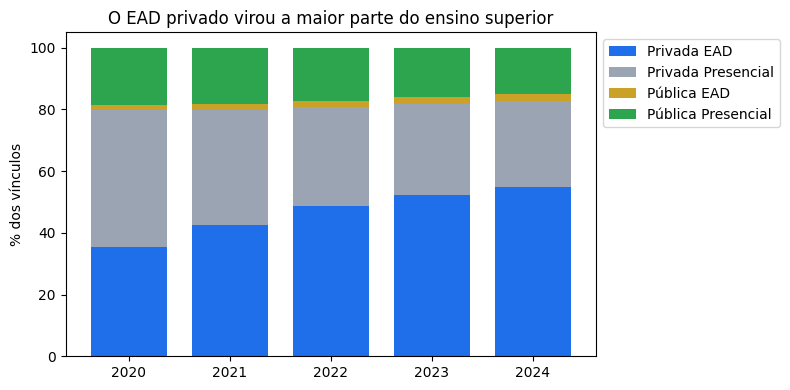

,ano,segmento,ingressantes,vinculos,% dos ingressantes,% dos vínculos
0,2020,Privada EAD,1960679,4463450,52.1,35.5
1,2020,Privada Presencial,1277790,5551998,33.9,44.2
2,2020,Pública EAD,48300,230267,1.3,1.8
3,2020,Pública Presencial,478706,2319121,12.7,18.5
16,2024,Privada EAD,3257810,8638936,65.0,55.0
17,2024,Privada Presencial,1177412,4382113,23.5,27.9
18,2024,Pública EAD,89763,326759,1.8,2.1
19,2024,Pública Presencial,485448,2371014,9.7,15.1


In [ ]:
participacao['% dos ingressantes'] = 100 * participacao['ingressantes'] / participacao.groupby('ano')['ingressantes'].transform('sum')
participacao['% dos vínculos'] = 100 * participacao['vinculos'] / participacao.groupby('ano')['vinculos'].transform('sum')

fatia = participacao.pivot(index='ano', columns='segmento', values='% dos vínculos')[SEGMENTOS]
ax = fatia.plot.bar(stacked=True, figsize=(8, 4), color=[CORES[s] for s in SEGMENTOS], width=0.75)
ax.set_ylabel('% dos vínculos')
ax.set_xlabel('')
ax.set_title('O EAD privado virou a maior parte do ensino superior')
ax.legend(bbox_to_anchor=(1, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

ead = participacao[participacao['segmento'] == 'Privada EAD'].set_index('ano')
RESUMO['vinculos_ead_2020'] = ead.loc[2020, '% dos vínculos']
RESUMO['vinculos_ead_2024'] = ead.loc[2024, '% dos vínculos']
RESUMO['ingressantes_ead_2024_pct'] = ead.loc[2024, '% dos ingressantes']
RESUMO['ingressantes_ead_2024'] = int(ead.loc[2024, 'ingressantes'])

participacao[participacao['ano'].isin([2020, 2024])].round(1)

### 2.2 Desvínculo por segmento

Taxa de desvínculo anual (`taxa_desvinculo`) por segmento. Para a série no tempo, só entram cursos presentes nos 5 anos e com 30 ou mais vínculos no ano. Assim ela não mistura cursos que abriram ou fecharam no meio do caminho.


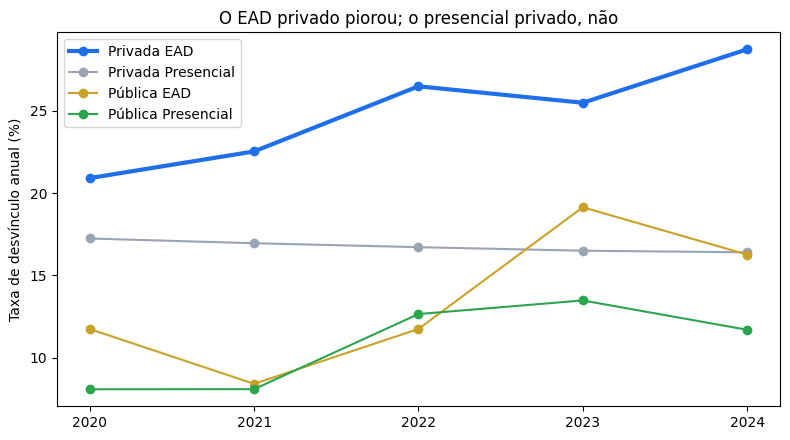

segmento,Privada EAD,Privada Presencial,Pública EAD,Pública Presencial
ano,,,,
2020,20.9,17.2,11.7,8.1
2021,22.5,17.0,8.4,8.1
2022,26.5,16.7,11.8,12.7
2023,25.5,16.5,19.1,13.5
2024,28.7,16.4,16.3,11.7


In [ ]:
estaveis = cursos_ano[(cursos_ano['presente_5_anos'] == 1) & (cursos_ano['poucos_alunos'] == 0)]
evolucao = taxa(estaveis, ['ano', 'segmento']).pivot(index='ano', columns='segmento', values='taxa_%')[SEGMENTOS]

fig, ax = plt.subplots(figsize=(8, 4.5))
for s in SEGMENTOS:
    ax.plot(evolucao.index, evolucao[s], marker='o', color=CORES[s], lw=3 if s == 'Privada EAD' else 1.5, label=s)
ax.set_xticks(evolucao.index)
ax.set_ylabel('Taxa de desvínculo anual (%)')
ax.set_title('O EAD privado piorou; o presencial privado, não')
ax.legend()
plt.tight_layout()
plt.show()

RESUMO['desv_ead_2020'] = evolucao.loc[2020, 'Privada EAD']
RESUMO['desv_ead_2024'] = evolucao.loc[2024, 'Privada EAD']
RESUMO['desv_pres_priv_2020'] = evolucao.loc[2020, 'Privada Presencial']
RESUMO['desv_pres_priv_2024'] = evolucao.loc[2024, 'Privada Presencial']
evolucao.round(1)

### 2.3 Efeito do crescimento do EAD

Quanto da alta de 2020 a 2024 vem só de o EAD privado ter crescido? A conta é simples: aplicar as taxas de 2024 de cada segmento ao tamanho que os segmentos tinham em 2020. Se a taxa geral ficar bem abaixo de 22,6%, parte da alta é efeito de mais gente estar no EAD privado. O resto é piora dentro dos segmentos.


In [ ]:
seg_ano = taxa(cursos_ano, ['ano', 'segmento'])
peso_2020 = seg_ano[seg_ano['ano'] == 2020].set_index('segmento')['vinculos']
taxa_2024 = seg_ano[seg_ano['ano'] == 2024].set_index('segmento')['taxa_%']

geral = taxa(cursos_ano, 'ano').set_index('ano')['taxa_%']
com_mix_2020 = (taxa_2024 * peso_2020).sum() / peso_2020.sum()

RESUMO['taxa_geral_2020'] = geral[2020]
RESUMO['taxa_geral_2024'] = geral[2024]
RESUMO['taxa_2024_mix_2020'] = com_mix_2020
parte_mix = (geral[2024] - com_mix_2020) / (geral[2024] - geral[2020])

print(f'Taxa geral 2020: {geral[2020]:.1f}%')
print(f'Taxa geral 2024: {geral[2024]:.1f}%')
print(f'Taxa 2024 se o tamanho dos segmentos fosse o de 2020: {com_mix_2020:.1f}%')
print(f'=> cerca de {100 * parte_mix:.0f}% da alta vem só do crescimento do EAD privado; o resto é piora dentro dos segmentos.')

Taxa geral 2020: 17.1%
Taxa geral 2024: 22.6%
Taxa 2024 se o tamanho dos segmentos fosse o de 2020: 20.0%
=> cerca de 47% da alta vem só do crescimento do EAD privado; o resto é piora dentro dos segmentos.


### 2.4 Desvínculo anual por segmento, todos os cursos (gráfico do slide 6)
Mesma medida da seção 2.2 (`taxa_desvinculo`, soma ÷ soma), mas com todos os cursos, como no gráfico do slide. A série de cursos estáveis (2.2) é a mais segura para a tendência; esta reproduz o número oficial do briefing.

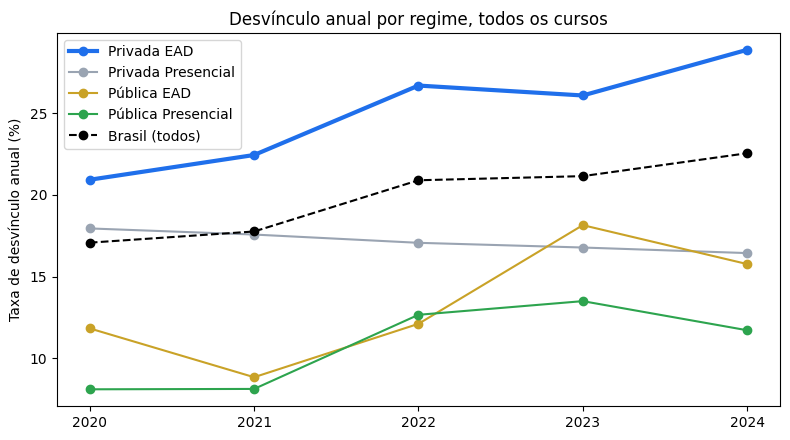

segmento,Privada EAD,Privada Presencial,Pública EAD,Pública Presencial,Brasil (todos)
ano,,,,,
2020,20.9,17.9,11.8,8.1,17.1
2021,22.4,17.6,8.8,8.1,17.8
2022,26.7,17.1,12.1,12.7,20.9
2023,26.1,16.8,18.1,13.5,21.1
2024,28.9,16.4,15.8,11.7,22.6


In [ ]:
todos = taxa(cursos_ano, ['ano', 'segmento']).pivot(index='ano', columns='segmento', values='taxa_%')[SEGMENTOS]
todos['Brasil (todos)'] = taxa(cursos_ano, 'ano').set_index('ano')['taxa_%']
fig, ax = plt.subplots(figsize=(8, 4.5))
for s in SEGMENTOS:
    ax.plot(todos.index, todos[s], marker='o', color=CORES[s], lw=3 if s == 'Privada EAD' else 1.5, label=s)
ax.plot(todos.index, todos['Brasil (todos)'], marker='o', color='black', ls='--', lw=1.5, label='Brasil (todos)')
ax.set_xticks(todos.index)
ax.set_ylabel('Taxa de desvínculo anual (%)')
ax.set_title('Desvínculo anual por regime, todos os cursos')
ax.legend()
plt.tight_layout()
plt.show()
todos.round(1)


### 2.5 De onde vêm os 5,5 p.p. de alta (slide 7)
A alta da taxa geral (17,1% → 22,6%) se divide em duas partes:
- **maior participação**: efeito de mudar o tamanho dos segmentos (taxa geral de 2024 menos a taxa de 2024 com o tamanho de 2020, seção 2.3). Quase todo esse efeito é o EAD privado crescendo;
- **piora da taxa do EAD privado**: quanto a taxa geral subiria só com a piora da taxa do EAD privado, mantendo o tamanho de 2020.

O resto é a piora (ou melhora) da taxa nos outros segmentos. Também mostra a fatia do EAD privado em todos os desvinculados de cada ano.

In [ ]:
tam_2020 = peso_2020 / peso_2020.sum()
taxa_2020 = seg_ano[seg_ano['ano'] == 2020].set_index('segmento')['taxa_%']
efeito_participacao = geral[2024] - com_mix_2020
efeito_taxa = tam_2020 * (taxa_2024 - taxa_2020)  # piora de cada segmento, com o tamanho de 2020
alta_total = geral[2024] - geral[2020]
decomposicao = pd.Series({
    'maior participação (tamanho dos segmentos)': efeito_participacao,
    'piora da taxa do EAD privado': efeito_taxa['Privada EAD'],
    'piora da taxa nos outros segmentos': efeito_taxa.drop('Privada EAD').sum(),
}, name='p.p.')
RESUMO['alta_total_pp'] = alta_total
RESUMO['alta_participacao_pp'] = efeito_participacao
RESUMO['alta_taxa_ead_pp'] = efeito_taxa['Privada EAD']
print(f'Alta total: {alta_total:.1f} p.p. | soma das partes: {decomposicao.sum():.1f} p.p.')
print(f"Participação + piora do EAD privado: {efeito_participacao + efeito_taxa['Privada EAD']:.1f} de {alta_total:.1f} p.p.")
display(decomposicao.round(1).to_frame())

desv_seg = cursos_ano.groupby(['ano', 'segmento'])['desvinculados'].sum().unstack()
fatia_desv = (100 * desv_seg['Privada EAD'] / desv_seg.sum(axis=1)).rename('% dos desvinculados que são do EAD privado')
RESUMO['fatia_desv_ead_2024'] = fatia_desv[2024]
fatia_desv.round(1).to_frame()


Alta total: 5.5 p.p. | soma das partes: 5.5 p.p.
Participação + piora do EAD privado: 5.4 de 5.5 p.p.


,p.p.
maior participação (tamanho dos segmentos),2.6
piora da taxa do EAD privado,2.8
piora da taxa nos outros segmentos,0.1


,% dos desvinculados que são do EAD privado
ano,
2020,43.5
2021,53.9
2022,62.1
2023,64.6
2024,70.4


## 3 · Afirmação 2: começo do curso

A desistência acontece no começo do curso.

A medida agora é a desistência acumulada por turma (`tda_%`): de cada 100 que entraram, quantos já desistiram. Só entram as turmas de 2015 a 2018, que têm 6 anos ou mais de acompanhamento, para comparar todas no mesmo prazo.


In [ ]:
base_turmas = traj[traj['turma_ingresso'].between(2015, 2018) & (traj['anos_desde_ingresso'] <= 6)]
curva = tda_media(base_turmas, ['segmento', 'anos_desde_ingresso']).drop(columns='ingressantes')
curva


,segmento,anos_desde_ingresso,tda_pct
0,Privada EAD,0,20.764559
1,Privada EAD,1,43.125109
2,Privada EAD,2,53.488260
3,Privada EAD,3,59.505593
4,Privada EAD,4,63.391264
5,Privada EAD,5,65.517395
6,Privada EAD,6,67.558857
7,Privada Presencial,0,13.939337
8,Privada Presencial,1,30.259513
9,Privada Presencial,2,42.163737


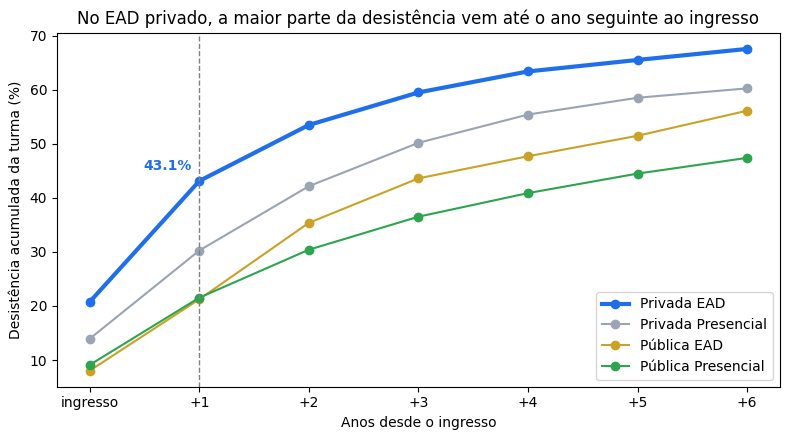

,0,1,6,% da desistência de 6 anos que já ocorreu até +1
segmento,,,,
Privada EAD,20.8,43.1,67.6,64.0
Privada Presencial,13.9,30.3,60.3,50.0
Pública EAD,8.0,21.2,56.1,38.0
Pública Presencial,9.1,21.5,47.4,45.0


In [ ]:
tab_curva = curva.pivot(index='anos_desde_ingresso', columns='segmento', values='tda_pct')[SEGMENTOS]

fig, ax = plt.subplots(figsize=(8, 4.5))
for s in SEGMENTOS:
    ax.plot(tab_curva.index, tab_curva[s], marker='o', color=CORES[s], lw=3 if s == 'Privada EAD' else 1.5, label=s)
ax.axvline(1, ls='--', color='gray', lw=1)
ax.annotate(f"{tab_curva.loc[1, 'Privada EAD']:.1f}%", (1, tab_curva.loc[1, 'Privada EAD']),
            textcoords='offset points', xytext=(-40, 8), color=CORES['Privada EAD'], weight='bold')
ax.set_xticks(tab_curva.index)
ax.set_xticklabels(['ingresso'] + [f'+{k}' for k in tab_curva.index[1:]])
ax.set_ylabel('Desistência acumulada da turma (%)')
ax.set_xlabel('Anos desde o ingresso')
ax.set_title('No EAD privado, a maior parte da desistência vem até o ano seguinte ao ingresso')
ax.legend()
plt.tight_layout()
plt.show()

RESUMO['tda_ead_ano0'] = tab_curva.loc[0, 'Privada EAD']
RESUMO['tda_ead_ano1'] = tab_curva.loc[1, 'Privada EAD']
RESUMO['tda_ead_ano6'] = tab_curva.loc[6, 'Privada EAD']
RESUMO['tda_pres_priv_ano1'] = tab_curva.loc[1, 'Privada Presencial']
RESUMO['tda_pres_pub_ano1'] = tab_curva.loc[1, 'Pública Presencial']

fracao_inicio = (tab_curva.loc[1] / tab_curva.loc[6] * 100).rename('% da desistência de 6 anos que já ocorreu até +1')
pd.concat([tab_curva.loc[[0, 1, 6]].T.round(1), fracao_inicio.round(0)], axis=1)

### 3.1 Ano em que a turma sai

`desistentes_no_ano ÷ ingressantes`: de cada 100 ingressantes, quantos saem em cada ano do curso.


In [ ]:
por_ano = base_turmas.groupby(['segmento', 'anos_desde_ingresso'], as_index=False)[['desistentes_no_ano', 'ingressantes']].sum()
por_ano['saem_no_ano_pct'] = 100.0 * por_ano['desistentes_no_ano'] / por_ano['ingressantes']
por_ano = por_ano[['segmento', 'anos_desde_ingresso', 'saem_no_ano_pct']]
por_ano


,segmento,anos_desde_ingresso,saem_no_ano_pct
0,Privada EAD,0,20.763383
1,Privada EAD,1,22.356475
2,Privada EAD,2,10.359202
3,Privada EAD,3,6.014167
4,Privada EAD,4,3.883736
5,Privada EAD,5,2.124957
6,Privada EAD,6,2.040190
7,Privada Presencial,0,13.938614
8,Privada Presencial,1,16.316899
9,Privada Presencial,2,11.899394


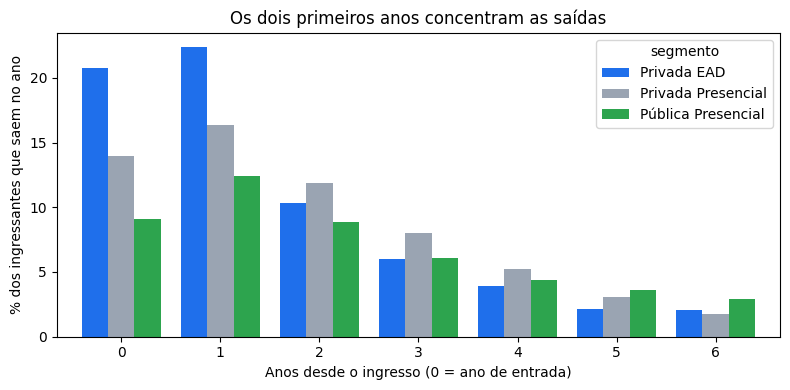

segmento,Privada EAD,Privada Presencial,Pública Presencial
anos_desde_ingresso,,,
0,20.8,13.9,9.1
1,22.4,16.3,12.4
2,10.4,11.9,8.9
3,6.0,8.0,6.1
4,3.9,5.2,4.4
5,2.1,3.1,3.6
6,2.0,1.7,2.9


In [ ]:
tab_ano = por_ano.pivot(index='anos_desde_ingresso', columns='segmento', values='saem_no_ano_pct')[['Privada EAD', 'Privada Presencial', 'Pública Presencial']]
ax = tab_ano.plot.bar(figsize=(8, 4), color=[CORES[s] for s in tab_ano.columns], width=0.8)
ax.set_xlabel('Anos desde o ingresso (0 = ano de entrada)')
ax.set_ylabel('% dos ingressantes que saem no ano')
ax.set_title('Os dois primeiros anos concentram as saídas')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
tab_ano.round(1)

### 3.2 Turmas novas saem antes?

Desistência acumulada até o fim do ano seguinte ao ingresso (`anos_desde_ingresso = 1`), turma por turma, no EAD privado. Todas as turmas de 2015 a 2020 já completaram esse prazo.


In [ ]:
ead_ano1 = traj[(traj['segmento'] == 'Privada EAD') & (traj['anos_desde_ingresso'] == 1)]
turmas = tda_media(ead_ano1, 'turma_ingresso', 'tda_ate_ano_seguinte_pct')
turmas['tda_ate_ano_seguinte_pct'] = turmas['tda_ate_ano_seguinte_pct'].round(1)
turmas


,turma_ingresso,ingressantes,tda_ate_ano_seguinte_pct
0,2015,696983,36.0
1,2016,835523,43.7
2,2017,1002142,44.5
3,2018,1338324,45.4
4,2019,1603883,41.4
5,2020,1984455,41.6


## 4 · Afirmação 3: tipo de faculdade

Não é só o tipo de faculdade.

O EAD privado poderia parecer pior só porque é oferecido por instituições diferentes (armadilha 2). Para testar isso, comparamos cursos EAD e presenciais da mesma instituição privada e da mesma turma.


In [ ]:
privada = traj[(traj['rede'] == 'Privada') & traj['anos_desde_ingresso'].isin([1, 4])]
por_modalidade = tda_media(privada, ['co_ies', 'turma_ingresso', 'anos_desde_ingresso', 'modalidade'], 'tda')
chave = ['co_ies', 'turma_ingresso', 'anos_desde_ingresso']
ead = por_modalidade[por_modalidade['modalidade'] == 'EAD'].drop(columns='modalidade')
presencial = por_modalidade[por_modalidade['modalidade'] == 'Presencial'].drop(columns='modalidade')

pares = ead.merge(presencial, on=chave, suffixes=('_ead', '_presencial'))
pares['diferenca_pp'] = pares['tda_ead'] - pares['tda_presencial']
pares = pares[chave + ['tda_ead', 'tda_presencial', 'diferenca_pp', 'ingressantes_ead', 'ingressantes_presencial']]
pares


,co_ies,turma_ingresso,anos_desde_ingresso,tda_ead,tda_presencial,diferenca_pp,ingressantes_ead,ingressantes_presencial
0,10,2018,1,11.719878,9.709790,2.010088,657,5850
1,10,2018,4,77.017930,22.840889,54.177041,657,5850
2,10,2019,1,41.763197,13.964525,27.798672,1542,6638
3,10,2019,4,78.988444,24.992626,53.995818,1542,6638
4,10,2020,1,60.314647,15.577519,44.737128,3994,5784
...,...,...,...,...,...,...,...,...
2395,21224,2020,4,47.060000,52.380000,-5.320000,51,21
2396,21573,2020,1,100.000000,47.054706,52.945294,9,34
2397,21573,2020,4,100.000000,100.000000,0.000000,9,34
2398,22248,2020,1,29.786429,23.680000,6.106429,350,38


In [ ]:
def resumo_pares(d):
    return pd.Series({
        'instituições': d['co_ies'].nunique(),
        'pares IES × turma': len(d),
        'EAD (%)': (d['tda_ead'] * d['ingressantes_ead']).sum() / d['ingressantes_ead'].sum(),
        'Presencial (%)': (d['tda_presencial'] * d['ingressantes_presencial']).sum() / d['ingressantes_presencial'].sum(),
        'diferença média na mesma IES (p.p.)': d['diferenca_pp'].mean(),
        'pares em que o EAD é pior (%)': 100 * (d['diferenca_pp'] > 0).mean(),
    })

mesma_ies = pd.DataFrame({k: resumo_pares(g) for k, g in pares.groupby('anos_desde_ingresso')}).T
mesma_ies.index = ['Fim do ano seguinte ao ingresso (+1)', '4 anos depois (+4)']
RESUMO['dif_mesma_ies_ano1'] = mesma_ies.iloc[0]['diferença média na mesma IES (p.p.)']
RESUMO['pares_ead_pior_ano1'] = mesma_ies.iloc[0]['pares em que o EAD é pior (%)']
mesma_ies.round(1)


,instituições,pares IES × turma,EAD (%),Presencial (%),diferença média na mesma IES (p.p.),pares em que o EAD é pior (%)
Fim do ano seguinte ao ingresso (+1),356.0,1200.0,42.9,31.6,7.8,68.7
4 anos depois (+4),356.0,1200.0,64.7,57.1,9.5,73.4


## 5 · Afirmação 4: perfil do aluno

O aluno é adulto, veio da escola pública e quase não tem apoio.

Perfil dos matriculados em 2024, em % das matrículas de cada segmento. Descreve quem está matriculado, não quem saiu.


In [ ]:
c24 = cursos_ano[cursos_ano['ano'] == 2024]
perfil = pd.DataFrame({
    '% dos ingressantes': 100 * c24.groupby('segmento')['ingressantes'].sum() / c24['ingressantes'].sum(),
    '25 anos ou mais': pct(c24, 'segmento', 'mat_25_anos_ou_mais', 'matriculas'),
    'escola pública': pct(c24, 'segmento', 'mat_escola_publica', 'matriculas'),
    'mulheres': pct(c24, 'segmento', 'mat_feminino', 'matriculas'),
    'ProUni': pct(c24, 'segmento', 'mat_prouni', 'matriculas'),
    'FIES': pct(c24, 'segmento', 'mat_fies', 'matriculas'),
    'apoio social': pct(c24, 'segmento', 'mat_apoio_social', 'matriculas'),
    'desvínculo anual': taxa(c24, 'segmento').set_index('segmento')['taxa_%'],
}).loc[SEGMENTOS]

RESUMO['ead_25mais'] = perfil.loc['Privada EAD', '25 anos ou mais']
RESUMO['ead_escola_publica'] = perfil.loc['Privada EAD', 'escola pública']
RESUMO['ead_prouni'] = perfil.loc['Privada EAD', 'ProUni']
RESUMO['ead_apoio'] = perfil.loc['Privada EAD', 'apoio social']
RESUMO['pub_pres_apoio'] = perfil.loc['Pública Presencial', 'apoio social']
perfil.round(1)

,% dos ingressantes,25 anos ou mais,escola pública,mulheres,ProUni,FIES,apoio social,desvínculo anual
segmento,,,,,,,,
Privada EAD,65.0,73.9,81.2,60.6,2.7,0.0,1.0,28.9
Privada Presencial,23.5,38.1,65.4,62.0,9.4,4.8,2.8,16.4
Pública EAD,1.8,83.3,79.4,59.5,0.0,0.0,3.6,15.8
Pública Presencial,9.7,35.9,65.9,52.5,0.0,0.1,22.0,11.7


Dois cuidados: `mat_apoio_social` na rede privada muda de coleta em 2023 (compare só 2023 com 2024), e um zero pode ser "não informado".


### 5.1 Idade e evasão (INEP)

Esta é a evasão do ensino superior (`fluxo_inep_contexto`, Brasil), a única fonte com recorte por idade de quem sai. Não compare o valor com as taxas acima: a metodologia é outra.


In [ ]:
f = fluxo_inep_contexto
f = f[(f['nivel'] == 'brasil') & (f['indicador'] == 'evasao') & (f['dimensao'] == 'Faixa de Idade')
      & f['ano_fluxo'].isin(['2019-2020', '2023-2024'])]
idade = f.pivot_table(index='categoria', columns='ano_fluxo', values='taxa', aggfunc='max')
idade.columns = ['evasao_2019_2020', 'evasao_2023_2024']
ordem = ['Até 19 anos'] + sorted(c for c in idade.index if c != 'Até 19 anos')
idade = idade.loc[ordem].rename_axis('faixa_de_idade').reset_index()
idade


,faixa_de_idade,evasao_2019_2020,evasao_2023_2024
0,Até 19 anos,8.7,9.4
1,20 a 22 anos,9.5,11.0
2,23 e 24 anos,12.3,15.3
3,25 a 29 anos,15.3,20.3
4,30 a 39 anos,16.3,22.5
5,40 a 49 anos,16.0,22.3
6,50 anos ou mais,16.2,23.4


## 6 · Afirmação 5a: risco previsível

O risco é previsível, e o começo define o resultado.

A IA mentora aposta em prever e agir cedo. Os dados públicos não têm informação por aluno, mas dá para testar duas ideias no nível da turma (curso × turma do EAD privado, turmas de 2015 a 2018, 30 ou mais ingressantes).


In [ ]:
ead_turmas = traj[(traj['segmento'] == 'Privada EAD') & traj['turma_ingresso'].between(2015, 2018)]
chave = ['co_curso', 'turma_ingresso']
cedo_tarde = pd.DataFrame({
    'ingressantes': ead_turmas.groupby(chave)['ingressantes'].max(),
    'tda_ano1': ead_turmas[ead_turmas['anos_desde_ingresso'] == 1].groupby(chave)['tda_%'].max(),
    'tda_ano6': ead_turmas[ead_turmas['anos_desde_ingresso'] == 6].groupby(chave)['tda_%'].max(),
})
cedo_tarde = cedo_tarde[cedo_tarde['ingressantes'] >= 30].reset_index()
cedo_tarde


,co_curso,turma_ingresso,ingressantes,tda_ano1,tda_ano6
0,48110,2015,218,58.72,68.35
1,48110,2016,97,52.08,63.54
2,48110,2017,63,39.68,69.84
3,48110,2018,43,48.84,62.79
4,65428,2015,1021,44.76,67.48
...,...,...,...,...,...
5005,5001329,2018,104,49.04,76.92
5006,5001334,2015,225,25.78,71.11
5007,5001334,2016,575,42.96,76.70
5008,5001334,2017,898,39.42,70.04


### 6.1 Risco se repete na turma?

Se o curso que perdeu muitos calouros numa turma também perde na seguinte, a instituição consegue prever onde o risco vai estar e priorizar a mentora antes de a turma começar.


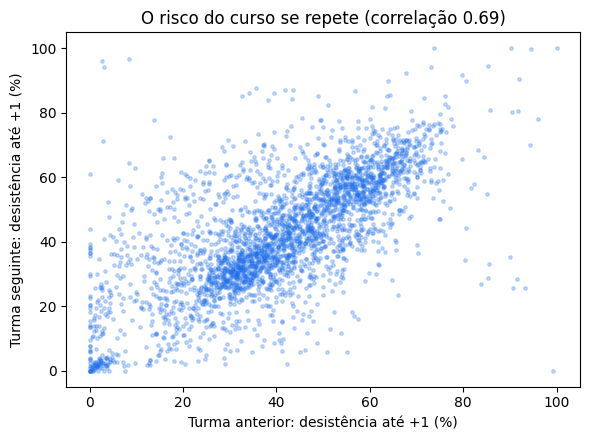

Pares de turmas consecutivas do mesmo curso: 2,962


In [ ]:
seq = cedo_tarde[['co_curso', 'turma_ingresso', 'tda_ano1']].dropna()
seq = seq.merge(seq.assign(turma_ingresso=seq['turma_ingresso'] + 1), on=['co_curso', 'turma_ingresso'],
                suffixes=('', '_turma_anterior'))
RESUMO['corr_turma_anterior'] = seq['tda_ano1'].corr(seq['tda_ano1_turma_anterior'])

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(seq['tda_ano1_turma_anterior'], seq['tda_ano1'], s=6, alpha=0.25, color=CORES['Privada EAD'])
ax.set_xlabel('Turma anterior: desistência até +1 (%)')
ax.set_ylabel('Turma seguinte: desistência até +1 (%)')
ax.set_title(f"O risco do curso se repete (correlação {RESUMO['corr_turma_anterior']:.2f})")
plt.tight_layout()
plt.show()
print(f"Pares de turmas consecutivas do mesmo curso: {len(seq):,}")

### 6.2 Perda no começo não volta

Os cursos foram divididos em 5 grupos pela desistência até o fim do ano seguinte ao ingresso. Para cada grupo, a barra mostra quanto da turma saiu até +1 e quanto saiu depois (de +1 a +6).


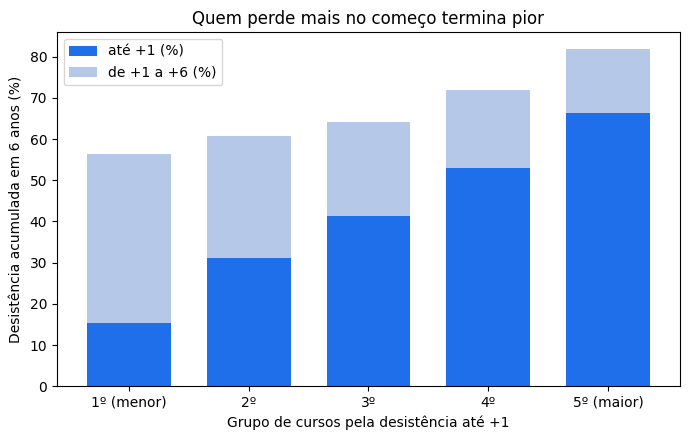

,turmas,até +1 (%),de +1 a +6 (%),total em 6 anos (%)
grupo,,,,
1º (menor),1002.0,15.3,41.1,56.5
2º,1002.0,31.1,29.8,60.9
3º,1002.0,41.4,22.7,64.1
4º,1002.0,52.9,19.0,72.0
5º (maior),1002.0,66.2,15.6,81.8


In [ ]:
d = cedo_tarde.dropna(subset=['tda_ano1', 'tda_ano6']).copy()
d['depois'] = d['tda_ano6'] - d['tda_ano1']
d['grupo'] = pd.qcut(d['tda_ano1'].rank(method='first'), 5,
                     labels=['1º (menor)', '2º', '3º', '4º', '5º (maior)'])

def ponderado(g, col):
    return (g[col] * g['ingressantes']).sum() / g['ingressantes'].sum()

quintos = pd.DataFrame({grupo: {
    'turmas': len(g),
    'até +1 (%)': ponderado(g, 'tda_ano1'),
    'de +1 a +6 (%)': ponderado(g, 'depois'),
    'total em 6 anos (%)': ponderado(g, 'tda_ano6'),
} for grupo, g in d.groupby('grupo', observed=True)}).T.rename_axis('grupo')
RESUMO['quinto_menor_6anos'] = quintos.iloc[0]['total em 6 anos (%)']
RESUMO['quinto_maior_6anos'] = quintos.iloc[-1]['total em 6 anos (%)']
RESUMO['quinto_menor_depois'] = quintos.iloc[0]['de +1 a +6 (%)']
RESUMO['quinto_maior_depois'] = quintos.iloc[-1]['de +1 a +6 (%)']

ax = quintos[['até +1 (%)', 'de +1 a +6 (%)']].plot.bar(stacked=True, figsize=(7, 4.5),
                                                        color=[CORES['Privada EAD'], '#b6c8e8'], width=0.7)
ax.set_xlabel('Grupo de cursos pela desistência até +1')
ax.set_ylabel('Desistência acumulada em 6 anos (%)')
ax.set_title('Quem perde mais no começo termina pior')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
quintos.round(1)


Duas leituras desta tabela:

1. O começo define o resultado. O grupo que mais perde até +1 termina os 6 anos muito acima do que menos perde. A diferença criada no começo não se recupera depois.
2. O risco não some depois do 1º ano, só muda de momento. Os cursos que perdem pouco no começo perdem mais depois. Por isso o acompanhamento tem que ser contínuo (mensal), e não só na matrícula.


## 7 · Afirmação 5b: poucos parceiros

Poucos parceiros alcançam a maior parte do problema.

Participação de cada instituição nos vínculos do EAD privado em 2024. Algumas redes aparecem com mais de um código de instituição, então a concentração por grupo é ainda maior.


In [ ]:
ead_2024 = cursos_ano[(cursos_ano['ano'] == 2024) & (cursos_ano['segmento'] == 'Privada EAD')]
concentracao = ead_2024.groupby('nome_ies', as_index=False)['vinculos'].sum().rename(columns={'vinculos': 'vinculos_ead'})
concentracao['pct_do_ead_privado'] = (100.0 * concentracao['vinculos_ead'] / concentracao['vinculos_ead'].sum()).round(1)
concentracao = concentracao.sort_values('vinculos_ead', ascending=False).head(10).reset_index(drop=True)
concentracao


,nome_ies,vinculos_ead,pct_do_ead_privado
0,Universidade Pitágoras Unopar Anhanguera,1358750,15.7
1,CENTRO UNIVERSITÁRIO LEONARDO DA VINCI,968632,11.2
2,UNIVERSIDADE CESUMAR,884180,10.2
3,UNIVERSIDADE ESTÁCIO DE SÁ,829102,9.6
4,CENTRO UNIVERSITÁRIO INTERNACIONAL,636253,7.4
5,UNIVERSIDADE PAULISTA,286013,3.3
6,CENTRO UNIVERSITÁRIO ESTÁCIO DE RIBEIRÃO PRETO,246289,2.9
7,UNIVERSIDADE CRUZEIRO DO SUL,238267,2.8
8,CENTRO UNIVERSITÁRIO ESTÁCIO DE SANTA CATARINA...,233556,2.7
9,UNIVERSIDADE CIDADE DE SÃO PAULO,130408,1.5


In [ ]:
concentracao['% acumulado'] = concentracao['pct_do_ead_privado'].cumsum()
RESUMO['top5'] = concentracao['% acumulado'].iloc[4]
RESUMO['top10'] = concentracao['% acumulado'].iloc[9]
print(f"5 instituições: {RESUMO['top5']:.0f}% dos vínculos do EAD privado | 10 instituições: {RESUMO['top10']:.0f}%")
concentracao

5 instituições: 54% dos vínculos do EAD privado | 10 instituições: 67%


,nome_ies,vinculos_ead,pct_do_ead_privado,% acumulado
0,Universidade Pitágoras Unopar Anhanguera,1358750,15.7,15.7
1,CENTRO UNIVERSITÁRIO LEONARDO DA VINCI,968632,11.2,26.9
2,UNIVERSIDADE CESUMAR,884180,10.2,37.1
3,UNIVERSIDADE ESTÁCIO DE SÁ,829102,9.6,46.7
4,CENTRO UNIVERSITÁRIO INTERNACIONAL,636253,7.4,54.1
5,UNIVERSIDADE PAULISTA,286013,3.3,57.4
6,CENTRO UNIVERSITÁRIO ESTÁCIO DE RIBEIRÃO PRETO,246289,2.9,60.3
7,UNIVERSIDADE CRUZEIRO DO SUL,238267,2.8,63.1
8,CENTRO UNIVERSITÁRIO ESTÁCIO DE SANTA CATARINA...,233556,2.7,65.8
9,UNIVERSIDADE CIDADE DE SÃO PAULO,130408,1.5,67.3


## 8 · Por que IA e quanto vale

Estas contas não são previsão. São ordens de grandeza, com premissas que o time pode mudar nas variáveis do começo de cada célula. Elas ajudam nos itens "Definir custos" e "Testar impacto" do plano.


### 8.1 Tutores necessários

Quantos tutores humanos seriam precisos para conversar todo mês com cada calouro?


In [ ]:
calouros = RESUMO['ingressantes_ead_2024']   # ingressantes do EAD privado em 2024 (dado do case)
minutos_por_conversa = 20                    # premissa: uma conversa mensal de 20 min
horas_uteis_tutor_mes = 120                  # premissa: horas de atendimento de um tutor por mês

horas_mes = calouros * minutos_por_conversa / 60
tutores = horas_mes / horas_uteis_tutor_mes
RESUMO['tutores_necessarios'] = tutores

print(f'Calouros do EAD privado (2024): {calouros:,.0f}')
print(f'Horas de conversa por mês: {horas_mes:,.0f}')
print(f'Tutores em tempo integral só para isso: {tutores:,.0f}')
print('=> Acompanhamento individual mensal nessa escala só é viável se a conversa for automatizada,')
print('   deixando o tutor humano para os casos que a IA sinaliza.')

Calouros do EAD privado (2024): 3,257,810
Horas de conversa por mês: 1,085,937
Tutores em tempo integral só para isso: 9,049
=> Acompanhamento individual mensal nessa escala só é viável se a conversa for automatizada,
   deixando o tutor humano para os casos que a IA sinaliza.


### 8.2 Alunos a mais por turma

Quantos alunos a mais seguiriam no curso, por turma? Os efeitos vêm de programas com acompanhamento ativo citados na pesquisa do time (conferir os originais antes de levar ao slide):

- coaching remoto InsideTrack: +5,2 p.p. de permanência (estudo randomizado);
- Georgia State, alertas preditivos + orientadores: +7 p.p. na graduação;
- cenário conservador: +2 p.p.


In [ ]:
cenarios = pd.DataFrame({'efeito (p.p.)': [2.0, 5.2, 7.0]},
                        index=['conservador', 'InsideTrack', 'Georgia State'])
cenarios['alunos a mais no curso por turma'] = (calouros * cenarios['efeito (p.p.)'] / 100).round(-3).astype(int)
cenarios['desistência até +1 do EAD privado (%)'] = (RESUMO['tda_ead_ano1'] - cenarios['efeito (p.p.)']).round(1)
cenarios

,efeito (p.p.),alunos a mais no curso por turma,desistência até +1 do EAD privado (%)
conservador,2.0,65000,41.1
InsideTrack,5.2,169000,37.9
Georgia State,7.0,228000,36.1


### 8.3 Tamanho do piloto

Desenho: sortear metade dos calouros de uma instituição parceira para usar a mentora e comparar com a outra metade. Indicador: `tda_%` até o fim do ano seguinte ao ingresso. Quantos calouros por grupo são precisos para detectar a queda com 95% de confiança e 80% de poder?


In [ ]:
def n_por_grupo(p0, queda_pp, z_alfa=1.96, z_poder=0.84):
    p1 = p0 - queda_pp / 100
    pm = (p0 + p1) / 2
    n = (z_alfa * math.sqrt(2 * pm * (1 - pm)) + z_poder * math.sqrt(p0 * (1 - p0) + p1 * (1 - p1))) ** 2 / (p0 - p1) ** 2
    return math.ceil(n)

base = RESUMO['tda_ead_ano1'] / 100
piloto = pd.DataFrame({'queda que queremos detectar (p.p.)': [3, 5, 7]})
piloto['calouros por grupo'] = piloto['queda que queremos detectar (p.p.)'].apply(lambda q: n_por_grupo(base, q))
piloto['total no piloto'] = 2 * piloto['calouros por grupo']
RESUMO['piloto_5pp'] = int(piloto.loc[1, 'total no piloto'])
piloto

,queda que queremos detectar (p.p.),calouros por grupo,total no piloto
0,3,4233,8466
1,5,1512,3024
2,7,765,1530
